In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# Step 1: Data processing
patients = pd.read_csv('/content/patients.csv')
diagnoses = pd.read_csv('/content/diagnoses.csv')
labs = pd.read_csv('/content/labs.csv')
outcomes = pd.read_csv('/content/outcomes.csv')

In [ ]:
# Merging the patients table with diagnoses and outcome table on Basis of DiagnosisID and OutcomeID
patients = patients.merge(diagnoses, on = 'DiagnosisID')
patients = patients.merge(outcomes, on = 'OutcomeID')

In [ ]:
# Converting AdmissionDate and DischargeDate to Date Time\
patients['AdmissionDate'] = pd.to_datetime(patients['AdmissionDate'])
patients['DischargeDate'] = pd.to_datetime(patients['DischargeDate'])

In [ ]:
# Calculating the number of days to stay in hospital.
# And converting it into days data type
patients['LengthOfStay'] = (patients['DischargeDate'] - patients['AdmissionDate']).dt.days

Our Machine would not be able to understand the things like Recovered, descreased , complicated so we have to mark some labels to it.
So we are marking Recovered = 0 and desceased and complicated = 1

In [ ]:
patients['OutcomeEncoded'] = patients['OutcomeName'].map(
    {
        'Recovered': 0,
        'Desceased': 1,
        'Complicated': 1
    }
)

In [ ]:
# debugging
patients['Age'].dtype

dtype('int64')

In [ ]:
# Creating a high risk indicator(age > 65 and Complicated or desceased)
patients['HighRisk'] = np.where((patients['Age'] > 65) | patients['OutcomeName'].isin({'Complicated', 'Desceased'}), 1, 0)

In [ ]:
# Feature Engineering
abnormal_condition = {
    'Blood Sugar' : lambda x: x > 120,
    'Cholestrol' : lambda x: x > 200,
    'Hemoglobin' : lambda x: x < 13
}

In [ ]:
def count_abnormal_labs(patient_id):
  patient_labs = labs[labs['PatientID'] == patient_id]
  count = 0

  for test_name, condition in abnormal_condition.items():
    test_results = patient_labs[patient_labs['TestName'] == test_name]
    count += test_results['Result'].apply(condition).sum()

  return count

patients['AbnormalCount'] = patients['PatientID'].apply(count_abnormal_labs)

In [ ]:
# Model training
feature = patients[['Age', 'LengthOfStay', 'AbnormalCount', 'TreatmentCost']]
target = patients['OutcomeEncoded']

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(feature, target, test_size =0.3, random_state=42)

In [ ]:
# debugging: Handling null values in y_train
y_train = y_train.fillna(0)

In [ ]:
model = LogisticRegression(max_iter= 500)
model.fit(x_train, y_train)

LogisticRegression(max_iter=500)

In [ ]:
# Debugging
y_test = y_test.fillna(0)

In [ ]:
y_pred = model.predict(x_test)
print('Classification Report: ')
print(classification_report(y_test, y_pred))

Classification Report: 
              precision    recall  f1-score   support

         0.0       0.71      0.98      0.82        42
         1.0       0.50      0.06      0.10        18

    accuracy                           0.70        60
   macro avg       0.60      0.52      0.46        60
weighted avg       0.64      0.70      0.60        60



Our model accuracy is very less due to shortage of data present with us.

We can increase accuracy by providing the large amount of dataset.

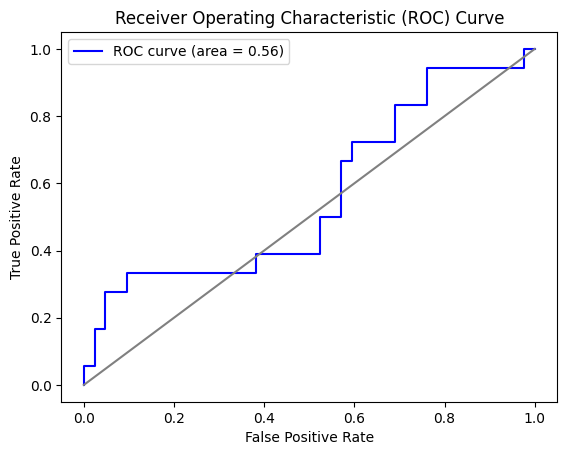

In [ ]:
# ROC Curves
from sklearn.metrics import roc_curve, auc

y_prob = model.predict_proba(x_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, color='blue', label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='-')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend()
plt.show()

In [ ]:
print(patients['HighRisk'].value_counts())
print(patients['HighRisk'].value_counts(normalize=True) * 100)

HighRisk
1    121
0     79
Name: count, dtype: int64
HighRisk
1    60.5
0    39.5
Name: proportion, dtype: float64


In [ ]:
import joblib

joblib.dump(model, 'logistic_model.pkl')

['logistic_model.pkl']

In [ ]:
pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 19.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 23.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


In [ ]:

import streamlit as st
import pandas as pd
import joblib

# Load Logistic Regression model
model = joblib.load("logistic_model.pkl")

st.set_page_config(
    page_title="Healthcare Risk Prediction",
    page_icon="🏥"
)

st.title("🏥 Healthcare Risk Prediction")
st.write("Predict patient outcomes using Logistic Regression.")

st.divider()

st.subheader("Enter Patient Details")

age = st.number_input("Age", min_value=0, max_value=120, value=35)

length_of_stay = st.number_input(
    "Length of Stay (Days)", min_value=0, value=5
)

abnormal_count = st.number_input(
    "Abnormal Lab Count", min_value=0, value=1
)

treatment_cost = st.number_input(
    "Treatment Cost (₹)", min_value=0.0, value=10000.0
)

if st.button("Predict Outcome"):

    input_data = pd.DataFrame(
        [[age, length_of_stay, abnormal_count, treatment_cost]],
        columns=[
            "Age",
            "LengthOfStay",
            "AbnormalCount",
            "TreatmentCost"
        ]
    )

    prediction = model.predict(input_data)[0]

    probabilities = model.predict_proba(input_data)[0]

    st.subheader("Prediction Result")

    if prediction == 1:
        st.error("Potential Complicated / Deceased Outcome")
    else:
        st.success("Predicted Outcome: Recovered")

    st.write("### Prediction Probabilities")

    probability_df = pd.DataFrame({
        "Outcome": ["Recovered", "Complicated / Deceased"],
        "Probability": probabilities
    })

    st.bar_chart(probability_df.set_index("Outcome"))

    st.write(
        f"Probability of Complicated / Deceased: "
        f"{probabilities[list(model.classes_).index(1)] * 100:.2f}%"
    )

st.caption("Educational ML project — not intended for clinical decisions.")

2026-11-01 02:05:06.048 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-01 02:05:06.050 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-01 02:05:06.325 
  command:

    streamlit run /usr/local/lib/python3.13/dist-packages/colab_kernel_launcher.py [ARGUMENTS]
2026-11-01 02:05:06.327 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-01 02:05:06.327 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-01 02:05:06.329 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-01 02:05:06.331 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when runn

DeltaGenerator()